### Imports & Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# project paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "TehranHouse.csv"

# visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

#display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)


print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH}")
print(f"Dataset exists: {DATA_PATH.exists()}")

Project root: d:\Estima\estima-real-estate-ml
Dataset path: d:\Estima\estima-real-estate-ml\data\raw\TehranHouse.csv
Dataset exists: True


### Load Dataset

In [2]:
df = pd.read_csv(DATA_PATH)

print(f"Data set shape: {df.shape}")
display(df.head())
df.info()


Data set shape: (3479, 8)


,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD)
0,63,1,True,True,True,Shahran,1.850000e+09,61666.67
1,60,1,True,True,True,Shahran,1.850000e+09,61666.67
2,79,2,True,True,True,Pardis,5.500000e+08,18333.33
3,95,2,True,True,True,Shahrake Qods,9.025000e+08,30083.33
4,123,2,True,True,True,Shahrake Gharb,7.000000e+09,233333.33


<class 'pandas.DataFrame'>
RangeIndex: 3479 entries, 0 to 3478
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Area        3479 non-null   str    
 1   Room        3479 non-null   int64  
 2   Parking     3479 non-null   bool   
 3   Warehouse   3479 non-null   bool   
 4   Elevator    3479 non-null   bool   
 5   Address     3456 non-null   str    
 6   Price       3479 non-null   float64
 7   Price(USD)  3479 non-null   float64
dtypes: bool(3), float64(2), int64(1), str(2)
memory usage: 146.2 KB


### Checking for missing value

In [3]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})
display(missing_summary)


,Missing Values,Missing Percentage
Area,0,0.00000
Room,0,0.00000
Parking,0,0.00000
Warehouse,0,0.00000
Elevator,0,0.00000
Address,23,0.66111
Price,0,0.00000
Price(USD),0,0.00000


### Checking for duplicates

In [4]:
duplicate_count = df.duplicated().sum()

print(f"Duplicated rows: {duplicate_count}")
print(f"Duplicate percentage: {duplicate_count / len(df) * 100:.2f}%")

Duplicated rows: 208
Duplicate percentage: 5.98%


### Analyze duplicate frequency

In [5]:
# Analyze duplicate frequency
duplicate_groups = (
    df.value_counts(dropna=False)
    .reset_index(name="Frequency")
    .query("Frequency > 1")
    .sort_values("Frequency", ascending=False)
)

print(f"Number of duplicate groups: {len(duplicate_groups)}")

display(duplicate_groups.head(10))

Number of duplicate groups: 161


,Area,Room,Parking,Warehouse,Elevator,Address,Price,Price(USD),Frequency
0,75,2,True,True,False,Shahr-e-Ziba,1.890000e+09,63000.00,14
1,57,1,True,True,True,Ostad Moein,1.600000e+09,53333.33,5
2,180,3,True,True,True,Pasdaran,9.900000e+09,330000.00,4
3,66,2,True,True,True,Ostad Moein,1.585000e+09,52833.33,4
4,87,2,True,True,True,Pardis,6.500000e+08,21666.67,4
5,68,2,True,True,True,Ostad Moein,1.970000e+09,65666.67,4
6,79,2,True,True,True,Pardis,5.500000e+08,18333.33,3
7,65,1,True,True,True,Shahran,1.880000e+09,62666.67,3
8,53,1,True,True,False,East Ferdows Boulevard,1.920000e+09,64000.00,3
9,74,2,True,True,True,Amirieh,1.700000e+09,56666.67,3


#### Statistics

In [6]:
# Descriptive statistics for numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Room,3479.0,2.079908e+00,7.582753e-01,0.0,2.000000e+00,2.000000e+00,2.000000e+00,5.000000e+00
Price,3479.0,5.359023e+09,8.099935e+09,3600000.0,1.418250e+09,2.900000e+09,6.000000e+09,9.240000e+10
Price(USD),3479.0,1.786341e+05,2.699978e+05,120.0,4.727500e+04,9.666667e+04,2.000000e+05,3.080000e+06


### Price distribution

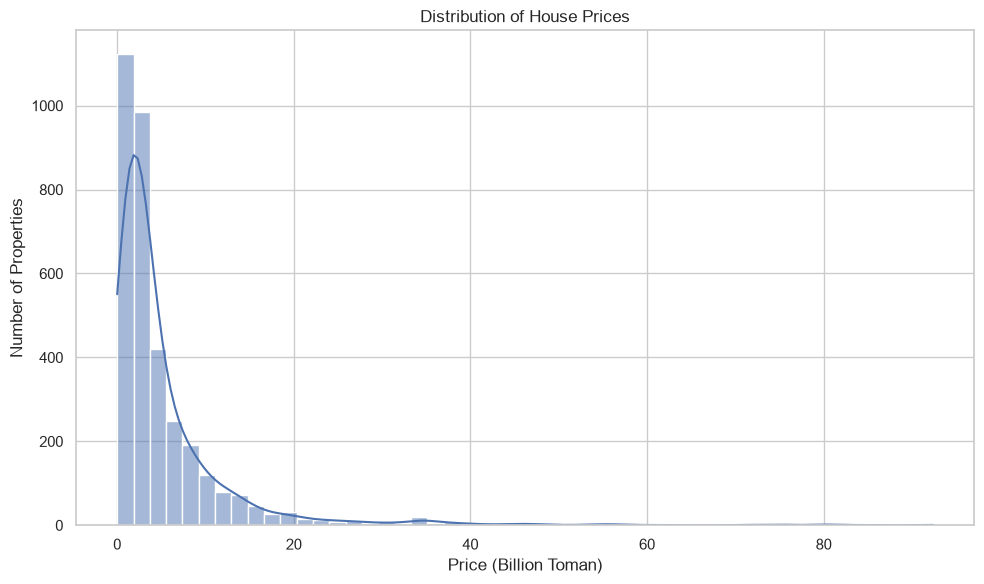

In [7]:
price_billion = df["Price"] / 1e9

plt.figure(figsize=(10, 6))

sns.histplot(
    price_billion,
    bins=50,
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Price (Billion Toman)")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

### Room distribution

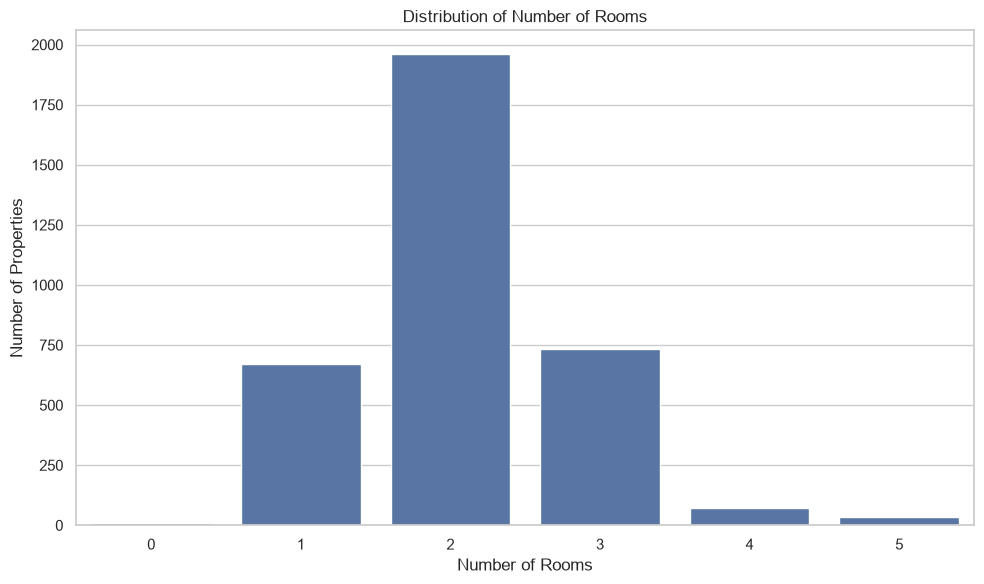

In [8]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Room",
    order=sorted(df["Room"].unique())
)

plt.title("Distribution of Number of Rooms")
plt.xlabel("Number of Rooms")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

### Inspect Area columns

In [9]:
print("Area data type:", df["Area"].dtype)

comma_count = df["Area"].str.contains(",", na=False).sum()

print(f"Values containing commas: {comma_count}")

display(
    df.loc[
        df["Area"].str.contains(",", na=False),
        ["Area", "Room", "Address", "Price"]
    ].head(10)
)

Area data type: str
Values containing commas: 6


,Area,Room,Address,Price
570,"3,310,000,000",2,Ostad Moein,3.310000e+09
709,"16,160,000,000",3,Pasdaran,1.616000e+10
807,"1,000",2,Damavand,7.000000e+09
1604,"8,400,000,000",2,Gheitarieh,8.700000e+09
2171,"3,600",2,Shahryar,9.720000e+09
2802,"2,550,000,000",2,Central Janatabad,2.550000e+09


### Convert Area to numeric(TEST)

In [10]:
area_numeric = (
    df["Area"]
    .str.strip()
    .str.replace(",", "", regex=False)
    .astype(float)
)

print("Area statistics:")
display(area_numeric.describe())

print("\nLargest Area values:")
display(
    df.loc[
        area_numeric.nlargest(10).index,
        ["Area", "Room", "Address", "Price"]
    ]
)

Area statistics:


count    3.479000e+03
mean     8.744000e+06
std      3.167266e+08
min      3.000000e+01
25%      6.900000e+01
50%      9.000000e+01
75%      1.200000e+02
max      1.616000e+10
Name: Area, dtype: float64


Largest Area values:


,Area,Room,Address,Price
709,"16,160,000,000",3,Pasdaran,1.616000e+10
1604,"8,400,000,000",2,Gheitarieh,8.700000e+09
570,"3,310,000,000",2,Ostad Moein,3.310000e+09
2802,"2,550,000,000",2,Central Janatabad,2.550000e+09
2171,"3,600",2,Shahryar,9.720000e+09
807,"1,000",2,Damavand,7.000000e+09
1694,929,5,Zafar,8.000000e+10
1974,900,3,Damavand,8.500000e+09
573,863,2,Gheitarieh,7.830000e+09
831,750,5,Mahmoudieh,7.500000e+10


### Inspect properties with unusually large areas

In [11]:
large_properties = df.loc[
    area_numeric > 500,
    ["Area", "Room", "Address", "Price"]
].copy()

large_properties["Area_numeric"] = area_numeric.loc[large_properties.index]

print(f"Number of properties with Area > 500: {len(large_properties)}")

display(
    large_properties.sort_values(
        "Area_numeric",
        ascending=False
    )
)

Number of properties with Area > 500: 23


,Area,Room,Address,Price,Area_numeric
709,"16,160,000,000",3,Pasdaran,1.616000e+10,1.616000e+10
1604,"8,400,000,000",2,Gheitarieh,8.700000e+09,8.400000e+09
570,"3,310,000,000",2,Ostad Moein,3.310000e+09,3.310000e+09
2802,"2,550,000,000",2,Central Janatabad,2.550000e+09,2.550000e+09
2171,"3,600",2,Shahryar,9.720000e+09,3.600000e+03
807,"1,000",2,Damavand,7.000000e+09,1.000000e+03
1694,929,5,Zafar,8.000000e+10,9.290000e+02
1974,900,3,Damavand,8.500000e+09,9.000000e+02
573,863,2,Gheitarieh,7.830000e+09,8.630000e+02
831,750,5,Mahmoudieh,7.500000e+10,7.500000e+02


### Analyze Area percentiles and large-area counts

In [12]:
area_percentiles = area_numeric.quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Area Percentiles:")
display(area_percentiles)

print("\nProperties above selected area thresholds:")

area_thresholds = [100, 200, 300, 500, 1000]

for threshold in area_thresholds:
    count = (area_numeric > threshold).sum()
    percentage = count / len(df) * 100

    print(
        f"Area > {threshold} m²: "
        f"{count} properties ({percentage:.2f}%)"
    )

Area Percentiles:


0.50     90.0
0.75    120.0
0.90    170.0
0.95    210.0
0.99    407.2
Name: Area, dtype: float64


Properties above selected area thresholds:
Area > 100 m²: 1355 properties (38.95%)
Area > 200 m²: 197 properties (5.66%)
Area > 300 m²: 67 properties (1.93%)
Area > 500 m²: 23 properties (0.66%)
Area > 1000 m²: 5 properties (0.14%)


### Area Distribution

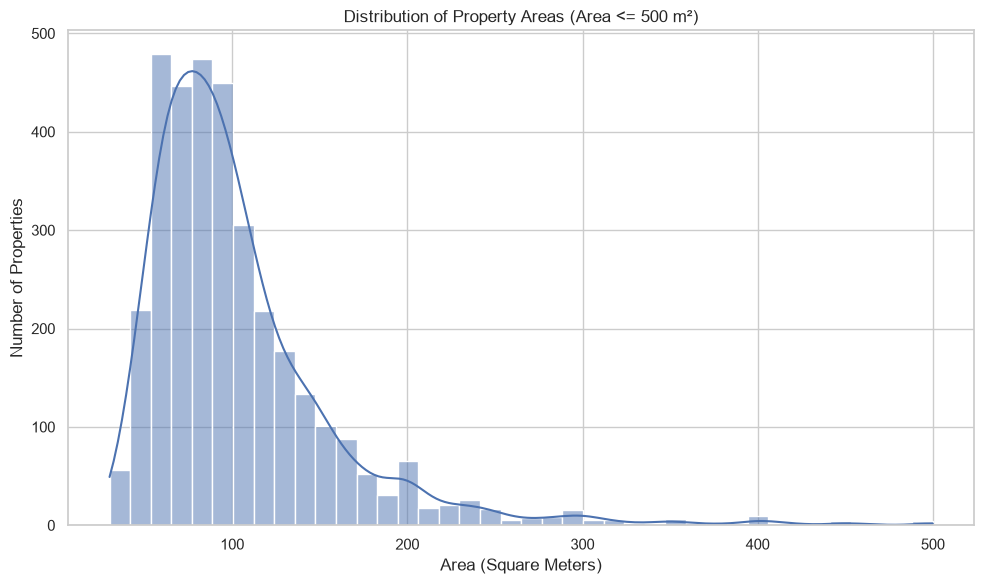

In [13]:
area_for_plot = area_numeric[area_numeric <= 500]

plt.figure(figsize=(10, 6))

sns.histplot(
    area_for_plot,
    bins=40,
    kde=True
)

plt.title("Distribution of Property Areas (Area <= 500 m²)")
plt.xlabel("Area (Square Meters)")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

### Analyze binary property features

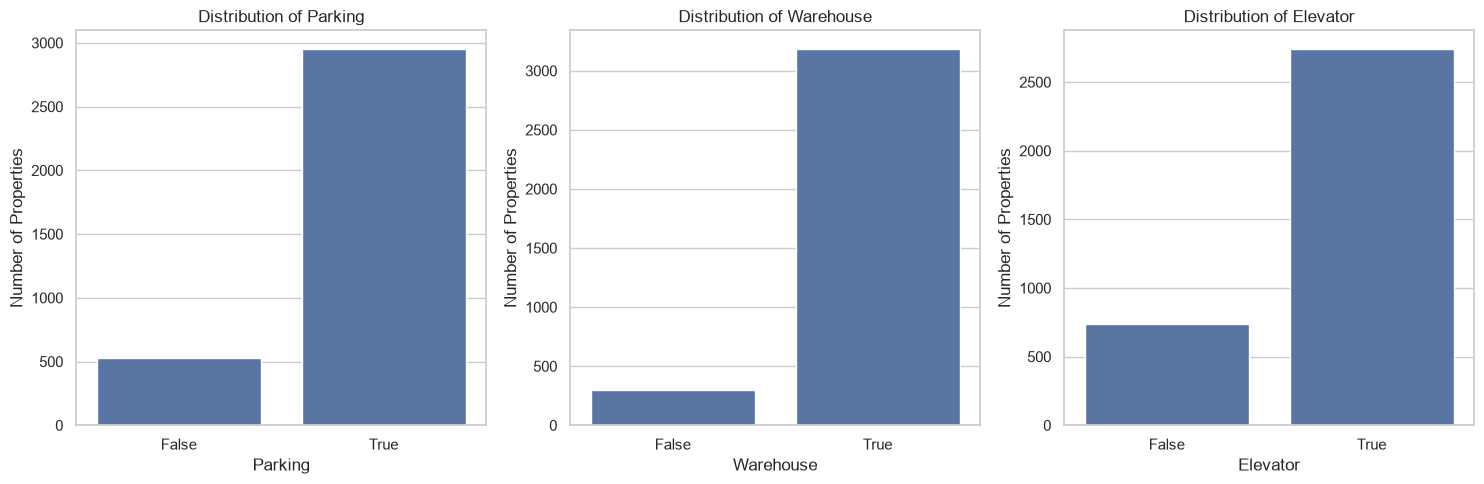

In [14]:
binary_features = ["Parking", "Warehouse", "Elevator"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for feature, ax in zip(binary_features, axes):
    sns.countplot(
        data=df,
        x=feature,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Properties")

plt.tight_layout()
plt.show()

### Address Distribution

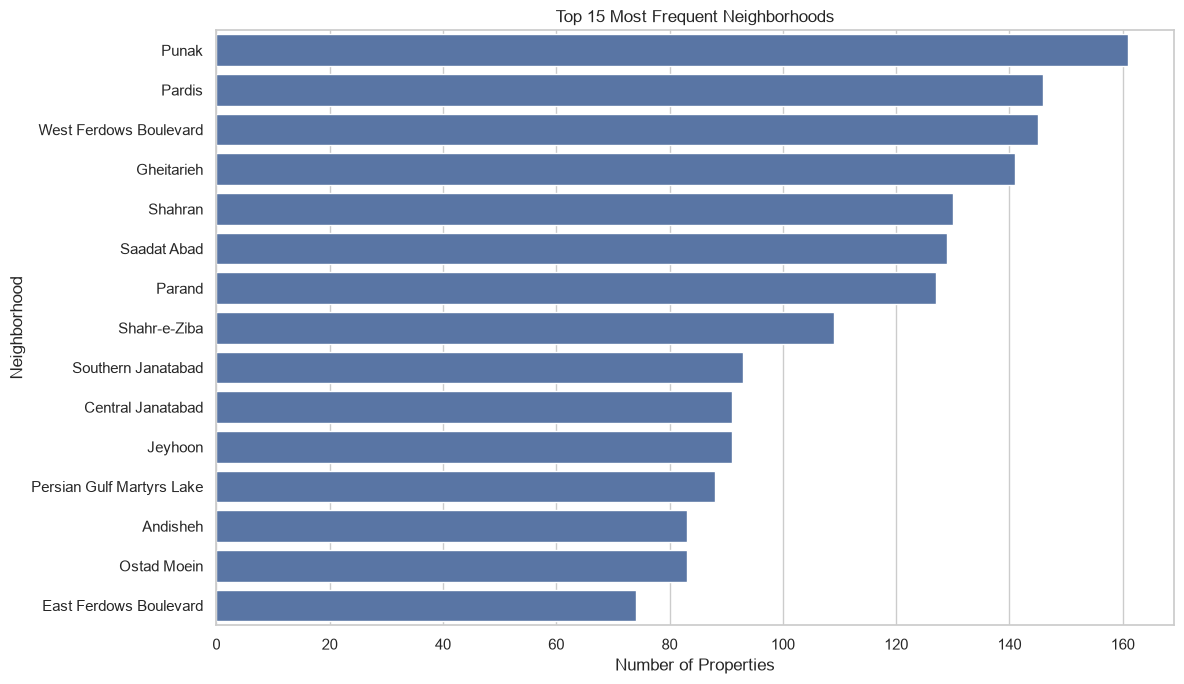

In [15]:
top_neighborhoods = df["Address"].value_counts().head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_neighborhoods.values,
    y=top_neighborhoods.index
)

plt.title("Top 15 Most Frequent Neighborhoods")
plt.xlabel("Number of Properties")
plt.ylabel("Neighborhood")

plt.tight_layout()
plt.show()

### Relation between Room and Price

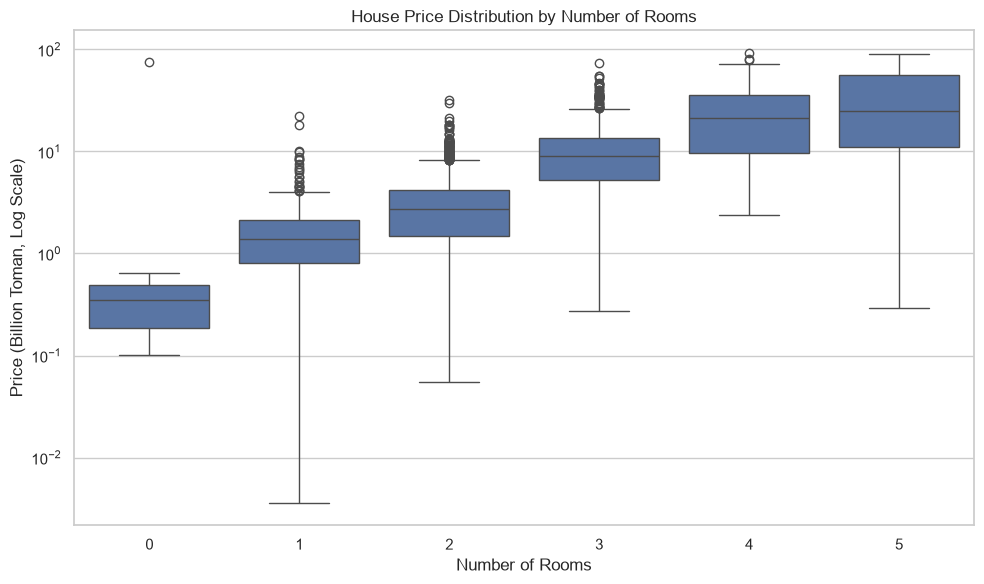

In [16]:
df_plot = df.copy()
df_plot["Price_Billion"] = df_plot["Price"] / 1e9

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_plot,
    x="Room",
    y="Price_Billion"
)

plt.yscale("log")

plt.title("House Price Distribution by Number of Rooms")
plt.xlabel("Number of Rooms")
plt.ylabel("Price (Billion Toman, Log Scale)")

plt.tight_layout()
plt.show()

In [17]:
room_price_summary = df.groupby("Room")["Price"].agg(
    ["count", "median", "mean", "min", "max"]
)

room_price_summary["median_billion"] = (
    room_price_summary["median"] / 1e9
)

room_price_summary["mean_billion"] = (
    room_price_summary["mean"] / 1e9
)

display(room_price_summary)

,count,median,mean,min,max,median_billion,mean_billion
Room,,,,,,,
0,10,3.525000e+08,7.860500e+09,1.020000e+08,7.560000e+10,0.3525,7.860500
1,673,1.380000e+09,1.703751e+09,3.600000e+06,2.250000e+10,1.3800,1.703751
2,1961,2.700000e+09,3.322727e+09,5.500000e+07,3.200000e+10,2.7000,3.322727
3,732,9.050000e+09,1.092580e+10,2.750000e+08,7.440000e+10,9.0500,10.925798
4,70,2.150000e+10,2.560033e+10,2.400000e+09,9.240000e+10,21.5000,25.600329
5,33,2.500000e+10,3.373439e+10,2.950000e+08,9.100000e+10,25.0000,33.734394


### Relation between Price and Features

In [18]:
binary_features = ["Parking", "Warehouse", "Elevator"]

for feature in binary_features:
    print(f"\nPrice Analysis by {feature}")

    summary = df.groupby(feature)["Price"].agg(
        ["count", "median", "mean"]
    )

    summary["median_billion"] = summary["median"] / 1e9
    summary["mean_billion"] = summary["mean"] / 1e9

    display(summary)


Price Analysis by Parking


,count,median,mean,median_billion,mean_billion
Parking,,,,,
False,529,9.400000e+08,1.723625e+09,0.9400,1.723625
True,2950,3.347500e+09,6.010930e+09,3.3475,6.010930



Price Analysis by Warehouse


,count,median,mean,median_billion,mean_billion
Warehouse,,,,,
False,297,1.145000e+09,2.459829e+09,1.145,2.459829
True,3182,3.100000e+09,5.629626e+09,3.100,5.629626



Price Analysis by Elevator


,count,median,mean,median_billion,mean_billion
Elevator,,,,,
False,740,1.500000e+09,3.622563e+09,1.5,3.622563
True,2739,3.400000e+09,5.828165e+09,3.4,5.828165


### Correlation Analysis

,Area,Room,Price
Area,1.000000,0.016436,0.021144
Room,0.016436,1.000000,0.567732
Price,0.021144,0.567732,1.000000


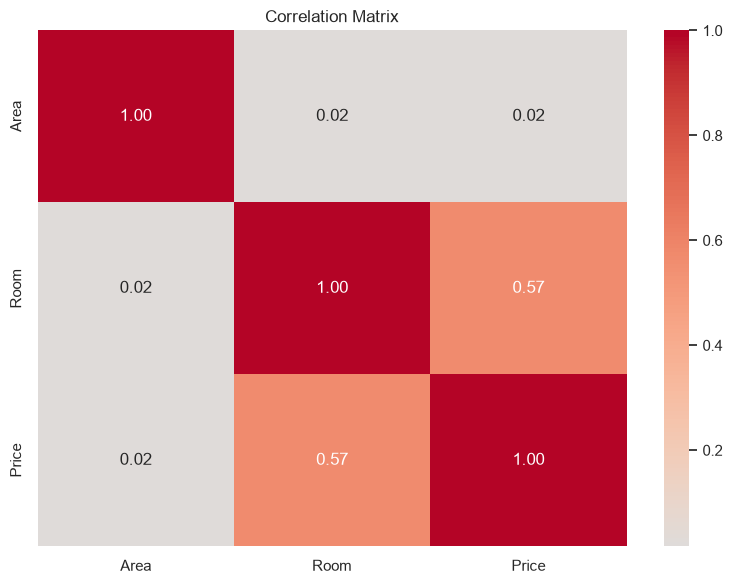

In [19]:
correlation_data = pd.DataFrame({
    "Area": area_numeric,
    "Room": df["Room"],
    "Price": df["Price"],
})

correlation_matrix = correlation_data.corr()

display(correlation_matrix)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

### Checking for Outlier sensitivity

In [20]:
suspected_error_indices = [709, 1604, 570, 2802]

correlation_data_clean = correlation_data.drop(
    index=suspected_error_indices
)

correlation_matrix_clean = correlation_data_clean.corr()

display(correlation_matrix_clean)

,Area,Room,Price
Area,1.000000,0.503269,0.548367
Room,0.503269,1.000000,0.567558
Price,0.548367,0.567558,1.000000


### Spearman Correlation

In [21]:
# مقاومتر در برابر outlier
spearman_matrix = correlation_data.corr(method="spearman")

display(spearman_matrix)

,Area,Room,Price
Area,1.000000,0.826133,0.706295
Room,0.826133,1.000000,0.601752
Price,0.706295,0.601752,1.000000


### Checking for relation between Price and Area(Numeric)

In [22]:
area_price_summary = pd.DataFrame({
    "Area": area_numeric,
    "Price": df["Price"]
})

area_price_summary["Price_per_sqm"] = (
    area_price_summary["Price"] / area_price_summary["Area"]
)

display(
    area_price_summary[
        ["Area", "Price", "Price_per_sqm"]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Area,3479.0,8.744000e+06,3.167266e+08,30.0,6.900000e+01,9.000000e+01,1.200000e+02,1.616000e+10
Price,3479.0,5.359023e+09,8.099935e+09,3600000.0,1.418250e+09,2.900000e+09,6.000000e+09,9.240000e+10
Price_per_sqm,3479.0,4.110229e+07,3.162247e+07,1.0,2.000000e+07,3.454545e+07,5.482676e+07,4.166667e+08


### Checking the Price in different Areas (1m each)

In [23]:
price_per_sqm_by_address = (
    df.assign(
        Area=area_numeric,
        Price_per_sqm=df["Price"] / area_numeric
    )
    .groupby("Address")["Price_per_sqm"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

display(price_per_sqm_by_address.head(15))

,count,median,mean
Address,,,
Gandhi,1,1.400000e+08,1.400000e+08
Vanak,2,1.274156e+08,1.274156e+08
Elahieh,17,1.145833e+08,1.122126e+08
Velenjak,22,1.008130e+08,1.116799e+08
Zaferanieh,27,1.000000e+08,1.137139e+08
Niavaran,68,1.000000e+08,1.027806e+08
Farmanieh,57,9.756098e+07,1.023298e+08
Kamranieh,14,9.357143e+07,1.036243e+08
Lavasan,4,8.666667e+07,1.172917e+08


In [24]:
area_price_corr = correlation_data[["Area", "Price"]].corr()

display(area_price_corr)

,Area,Price
Area,1.000000,0.021144
Price,0.021144,1.000000


In [25]:
correlation_data[["Area", "Room", "Price"]].corr(method="spearman")

,Area,Room,Price
Area,1.000000,0.826133,0.706295
Room,0.826133,1.000000,0.601752
Price,0.706295,0.601752,1.000000


## Exploratory Data Analysis (EDA) Summary

An exploratory analysis was performed on the Tehran housing dataset to understand its structure, data quality, feature distributions, and relationships with property prices.

### 1. Dataset Overview
- Dataset contains 3,479 records and 8 columns.
- Features include property area, number of rooms, parking, warehouse, elevator, and address.
- Target variable: `Price`.

### 2. Missing Values
- Identified 23 missing values in the `Address` column (approximately 0.66%).
- No missing values were found in other columns.

### 3. Duplicate Records
- Identified 208 duplicate rows (approximately 5.98%).
- Duplicate records were retained for further investigation rather than being removed automatically.

### 4. Feature Distributions
- `Area` contained comma-separated values and several suspicious entries.
- Most properties have between 1 and 3 rooms, with 2-room properties being the most common.
- Most properties have parking, a warehouse, and an elevator.
- The `Address` column contains 192 distinct neighborhoods.

### 5. Outlier Analysis
- Identified unusually large values in the `Area` column.
- Four extremely suspicious values appeared to result from data entry errors.
- Other large properties were retained because they could represent legitimate listings.
- The `Price` distribution showed considerable right skewness.

### 6. Feature Relationships
- `Area` and `Room` showed a strong positive monotonic relationship (Spearman correlation: 0.826).
- `Area` and `Price` also showed a positive monotonic relationship (Spearman correlation: 0.706).
- `Room` and `Price` had a positive correlation (Spearman correlation: 0.602).
- Larger properties and properties with more rooms generally had higher prices.

### 7. Price Analysis
- Median property price: approximately 2.9 billion IRR.
- Mean property price: approximately 5.36 billion IRR.
- Price per square meter varied considerably across neighborhoods.
- Some expensive neighborhoods showed higher median prices per square meter, although sample sizes varied.

### 8. Data Leakage Observation
- Identified `Price(USD)` as a derived feature based on `Price`.
- This feature was excluded during preprocessing to prevent target leakage.

### Conclusion

The EDA revealed important data quality issues, outliers, skewed distributions, and meaningful relationships between property characteristics and prices.

These findings guided the subsequent data cleaning and preprocessing stage.